# Statistics and Metric Geometry

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import seaborn as sns
from ipywidgets import interact, Dropdown

### Concept 1: Distance Metrics (Euclidean, Manhattan, and Mahalanobis)

#### What are Distance Metrics?

Distance metrics quantify the geometric separation between two data points or feature vectors $\mathbf{u}$ and $\mathbf{v}$.

1. **Euclidean Distance:** The straight-line ruler distance. It treats all feature directions equally and assumes dimensions are independent.
2. **Manhattan Distance:** The grid-based distance (sum of absolute coordinate differences). It is less sensitive to extreme outliers than Euclidean distance.
3. **The Flaw of Standard Distances:** Euclidean and Manhattan distances assume axes are completely independent and share identical scales. If feature 1 is measured in millimeters ($0$ to $10,000$) and feature 2 is measured in kilograms ($0$ to $2$), Euclidean distance is dominated entirely by feature 1. Furthermore, if features are strongly correlated, standard distance double-counts redundant information.
4. **Mahalanobis Distance:** The statistical distance that de-correlates features and standardizes their scale using the dataset's **Covariance Matrix** ($\Sigma$). It measures how many standard deviations away point $\mathbf{u}$ is from point $\mathbf{v}$ along the contours of the data distribution.

#### The Formulas

Given two $D$-dimensional vectors $\mathbf{u}$ and $\mathbf{v}$:

**1. Euclidean Distance ($L_2$ Distance):**


$$d_{\text{Euclidean}}(\mathbf{u}, \mathbf{v}) = \sqrt{\sum_{i=1}^{D} (u_i - v_i)^2} = \Vert{}\mathbf{u} - \mathbf{v}\Vert{}_2$$

**2. Manhattan Distance ($L_1$ Distance):**


$$d_{\text{Manhattan}}(\mathbf{u}, \mathbf{v}) = \sum_{i=1}^{D} \vert{}u_i - v_i\vert{} = \Vert{}\mathbf{u} - \mathbf{v}\Vert{}_1$$

**3. Mahalanobis Distance:**


$$d_{\text{Mahalanobis}}(\mathbf{u}, \mathbf{v}) = \sqrt{(\mathbf{u} - \mathbf{v})^\top \Sigma^{-1} (\mathbf{u} - \mathbf{v})}$$

#### How to read it out loud:

> *"The Mahalanobis distance between u and v equals the square root of the difference vector transposed, times the inverse covariance matrix, times the difference vector."*

#### Breakdown of every piece:

* **$\mathbf{u} - \mathbf{v}$**: The difference vector (shape $D \times 1$).
* **$\Sigma$**: The $D \times D$ sample covariance matrix of the dataset (from notebook 3).
* **$\Sigma^{-1}$**: The inverse of the covariance matrix (precision matrix). It automatically scales each axis by dividing by its variance and cancels out feature correlations.
* **If $\Sigma$ is the identity matrix $I$:** The Mahalanobis formula reduces exactly to the standard Euclidean distance.

#### Why AI Cares:

* **K-Nearest Neighbors (KNN) & Clustering (K-Means):** Distance metrics define cluster boundaries and neighbor assignments.
* **Anomaly & Outlier Detection:** A data point can look like a normal value on both features individually, but fall completely outside the correlation pattern; Mahalanobis distance flags this outlier immediately.
* **Metric Learning & Contrastive Loss:** Models like Siamese networks and CLIP optimize latent embedding spaces so that similar concepts have minimal distance.

#### NumPy Implementation

In [2]:

# 1. Define a synthetic dataset (100 samples, 2 correlated features)
# Feature 0: Height in cm, Feature 1: Weight in kg
np.random.seed(42)
mean = [170.0, 65.0]
# Covariance: Strong positive correlation between height and weight
cov = np.array([
    [25.0, 18.0],
    [18.0, 16.0]
])
data = np.random.multivariate_normal(mean, cov, size=100)

# Calculate dataset covariance matrix and its inverse
Sigma = np.cov(data, rowvar=False)
Sigma_inv = np.linalg.inv(Sigma)

# Two points to compare against the center point u
u = np.array([170.0, 65.0])       # Center point (mean)
v_normal = np.array([175.0, 69.0]) # Follows the positive correlation
v_outlier = np.array([175.0, 61.0]) # Violates the correlation (tall but very light)

def compute_distances(u, v, sigma_inv):
    diff = u - v
    
    # 1. Euclidean: sqrt(sum(diff^2))
    d_euclidean = np.sqrt(np.sum(diff ** 2))
    
    # 2. Manhattan: sum(|diff|)
    d_manhattan = np.sum(np.abs(diff))
    
    # 3. Mahalanobis: sqrt(diff.T @ Sigma_inv @ diff)
    d_mahalanobis = np.sqrt(diff.T @ sigma_inv @ diff)
    
    return d_euclidean, d_manhattan, d_mahalanobis

e_norm, m_norm, maha_norm = compute_distances(u, v_normal, Sigma_inv)
e_out, m_out, maha_out = compute_distances(u, v_outlier, Sigma_inv)

print(f"Point u (Center) : {u}\n")
print(f"Point v_normal   : {v_normal}")
print(f"Euclidean        : {e_norm:.4f}")
print(f"Manhattan        : {m_norm:.4f}")
print(f"Mahalanobis      : {maha_norm:.4f}\n")

print(f"Point v_outlier  : {v_outlier}")
print(f"Euclidean        : {e_out:.4f} (Nearly identical to normal!)")
print(f"Manhattan        : {m_out:.4f}")
print(f"Mahalanobis      : {maha_out:.4f} (Significantly larger due to variance/covariance!)")

Point u (Center) : [170.  65.]

Point v_normal   : [175.  69.]
Euclidean        : 6.4031
Manhattan        : 9.0000
Mahalanobis      : 1.2001

Point v_outlier  : [175.  61.]
Euclidean        : 6.4031 (Nearly identical to normal!)
Manhattan        : 9.0000
Mahalanobis      : 4.4729 (Significantly larger due to variance/covariance!)


In [5]:
sns.set_theme(style="whitegrid")
palette = sns.color_palette("deep")

# 1. Dataset & Covariance Setup
np.random.seed(42)
true_mean = np.array([170.0, 65.0])
true_cov = np.array([[25.0, 18.0], [18.0, 16.0]])
data = np.random.multivariate_normal(true_mean, true_cov, size=100)

Sigma = np.cov(data, rowvar=False)
Sigma_inv = np.linalg.inv(Sigma)

u = true_mean
test_points = {
    "v_normal (Follows Trend: 175cm, 69kg)": np.array([175.0, 69.0]),
    "v_outlier (Violates Trend: 175cm, 61kg)": np.array([175.0, 61.0])
}

# Eigendecomposition of covariance for drawing Mahalanobis ellipses
evals, evecs = np.linalg.eigh(Sigma)
angle = np.degrees(np.arctan2(evecs[1, 1], evecs[0, 1]))

def get_distances(u_pt, v_pt):
    diff = v_pt - u_pt
    d_euc = np.linalg.norm(diff)
    d_man = np.sum(np.abs(diff))
    d_mah = np.sqrt(diff.T @ Sigma_inv @ diff)
    return d_euc, d_man, d_mah

@interact(
    selected_point=Dropdown(
        options=list(test_points.keys()),
        value="v_normal (Follows Trend: 175cm, 69kg)",
        description="Inspect:"
    )
)
def plot_distance_geometry(selected_point):
    v = test_points[selected_point]
    d_euc, d_man, d_mah = get_distances(u, v)

    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={'width_ratios': [1.2, 0.9]})

    # -------------------------------------------------------------
    # Panel 1: 2D Feature Space (Data + Contours)
    # -------------------------------------------------------------
    # Scatter of dataset
    axes[0].scatter(
        data[:, 0], data[:, 1],
        color=palette[0], alpha=0.35, s=35, edgecolors="none",
        label="Dataset Samples (N=100)"
    )

    # Euclidean Iso-Distance Circle (Radius = Euclidean Distance of point v)
    euc_circle = plt.Circle(
        u, d_euc, color="gray", fill=False, linestyle="--", linewidth=1.8,
        label=f"Euclidean Circle (r = {d_euc:.2f})"
    )
    axes[0].add_patch(euc_circle)

    # Mahalanobis Iso-Distance Ellipses (1-sigma, 2-sigma, 3-sigma)
    for std_mult, alpha_val in [(1, 0.35), (2, 0.25), (3, 0.15)]:
        width = 2.0 * std_mult * np.sqrt(evals[1])
        height = 2.0 * std_mult * np.sqrt(evals[0])
        ell = Ellipse(
            xy=u, width=width, height=height, angle=angle,
            color=palette[2], fill=False, linewidth=1.5, linestyle="-.",
            label=f"Mahalanobis {std_mult}σ Ellipse" if std_mult == 1 else None
        )
        axes[0].add_patch(ell)

    # Manhattan Step Path (L-shape)
    axes[0].plot(
        [u[0], v[0], v[0]], [u[1], u[1], v[1]],
        color=palette[4], linestyle=":", linewidth=2.0,
        label=f"Manhattan Path (L1 = {d_man:.1f})"
    )

    # Euclidean Direct Line
    axes[0].plot(
        [u[0], v[0]], [u[1], v[1]],
        color="black", linestyle="-", linewidth=1.8,
        label=f"Euclidean Ray (L2 = {d_euc:.2f})"
    )

    # Mean Center Point
    axes[0].scatter([u[0]], [u[1]], color="black", s=100, zorder=6, label="Mean Center u (170, 65)")

    # Active Point Marker
    pt_color = "#2ca02c" if "normal" in selected_point else "#d62728"
    axes[0].scatter([v[0]], [v[1]], color=pt_color, s=120, zorder=7, edgecolors="black", linewidth=1.2)
    axes[0].annotate(
        f"v ({v[0]:.0f}, {v[1]:.0f})",
        (v[0], v[1]),
        textcoords="offset points", xytext=(12, 10 if v[1] >= u[1] else -18),
        fontsize=10, weight="bold", color=pt_color
    )

    axes[0].set_xlim(152, 188)
    axes[0].set_ylim(48, 82)
    axes[0].set_xlabel("Height (cm)", fontsize=11)
    axes[0].set_ylabel("Weight (kg)", fontsize=11)
    axes[0].set_title("Metric Geometry on Correlated Gaussian", fontsize=11, weight="bold")
    axes[0].legend(loc="upper left", frameon=True, fontsize=8.5)

    # -------------------------------------------------------------
    # Panel 2: Direct Metric Comparison (Bar Chart)
    # -------------------------------------------------------------
    metrics = ["Euclidean (L2)", "Manhattan (L1)", "Mahalanobis (DM)"]
    values = [d_euc, d_man, d_mah]
    bar_colors = ["gray", palette[4], pt_color]

    bars = axes[1].bar(metrics, values, color=bar_colors, width=0.45, edgecolor="black", alpha=0.85)

    for b in bars:
        h = b.get_height()
        axes[1].text(
            b.get_x() + b.get_width() / 2, h + 0.15,
            f"{h:.2f}", ha="center", va="bottom", fontsize=10, weight="bold"
        )

    axes[1].set_ylim(0, 11)
    axes[1].set_ylabel("Computed Distance Value", fontsize=11)
    axes[1].set_title("Distance Comparison", fontsize=11, weight="bold")

    fig.suptitle(
        f"Metric Sensitivity Check: {selected_point.split('(')[0].strip()}",
        fontsize=12, weight="bold"
    )

    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Inspect:', options=('v_normal (Follows Trend: 175cm, 69kg)', 'v_ou…

### Concept 2: Z-Score Standardization and Batch Centering

#### What is Z-Score Standardization?

Raw input data usually arrives with arbitrary scales and offsets across different features. For example, a house dataset might have:

* Feature 1: Number of bedrooms (values range between $1$ and $5$)
* Feature 2: Square footage (values range between $500$ and $5,000$)
* Feature 3: Price in dollars (values range between $100,000$ and $2,000,000$)

When features possess vastly different scales:

1. **Elongated Loss Landscapes:** The loss surface becomes a stretched, ill-conditioned ravine (like the one addressed with Momentum in Notebook 2). Gradients oscillate violently along high-scale features while crawling along low-scale features.
2. **Unfair Distance Weighting:** Distance metrics are overwhelmed by features with large numbers, rendering smaller features completely ignored.

**Z-Score Standardization (Standard Scaling)** solves this by transforming every feature independently so that:

1. **The Mean becomes $0.0$ (Zero Centering):** Subtracting the average shifts the distribution so the center sits right at the origin.
2. **The Variance becomes $1.0$ (Unit Scaling):** Dividing by the standard deviation squashes or stretches the values so $68\%$ of the data lies within the range $[-1, +1]$, and $95\%$ lies within $[-2, +2]$.

#### The Formulas

Given a feature column $\mathbf{x} = [x_1, x_2, \dots, x_N]^\top$:

**1. Calculate Mean ($\mu$) and Standard Deviation ($\sigma$):**


$$\mu = \frac{1}{N} \sum_{i=1}^{N} x_i$$

$$\sigma = \sqrt{\frac{1}{N} \sum_{i=1}^{N} (x_i - \mu)^2}$$

**2. Standardize Each Entry ($z_i$):**


$$z_i = \frac{x_i - \mu}{\sigma + \epsilon}$$

In matrix form for an entire mini-batch $X$ of shape $(N \times D)$:


$$Z = \frac{X - \boldsymbol{\mu}}{\boldsymbol{\sigma} + \epsilon}$$

#### How to read it out loud:

> *"The z-score of x_i equals x_i minus the mean mu, divided by the standard deviation sigma plus epsilon."*

#### Breakdown of every piece:

* **$x_i$**: The raw data value.
* **$\mu$** (*mu*): The sample mean (average position).
* **$x_i - \mu$**: The **centering step**. A positive value means the sample is above average; a negative value means it is below average.
* **$\sigma$** (*sigma*): The standard deviation (spread of the data).
* **$\epsilon$** (*epsilon*, e.g., $10^{-5}$): A tiny constant added to the denominator to prevent division by zero in case a feature is completely constant ($\sigma = 0$).
* **$z_i$**: The resulting standard score, measuring how many standard deviations $x_i$ is away from the mean.

#### Why AI Cares:

* **Batch Normalization (BatchNorm):** Applied between hidden layers in ConvNets to standardize activations across a mini-batch during the forward pass, smoothing optimization and speeding up training convergence.
* **Layer Normalization (LayerNorm) & RMSNorm:** Used inside modern Transformer architectures (like BERT, GPT, and LLaMA). Instead of standardizing across a batch, LayerNorm standardizes across all hidden channels for each individual token.
* **Symmetric Gradient Descent:** Standardizing inputs transforms elliptical contour lines into circular bowls, allowing optimizers to take direct paths straight to the global minimum with higher learning rates.

#### NumPy Implementation


In [6]:

# 1. Create an unstandardized synthetic dataset: 5 samples, 3 features
# Notice the wildly differing scales and offsets
X = np.array([
    [2.0, 1500.0, 300000.0],
    [4.0, 2400.0, 450000.0],
    [3.0, 1800.0, 350000.0],
    [5.0, 3200.0, 600000.0],
    [1.0,  900.0, 180000.0]
])

epsilon = 1e-5

# ==========================================
# Step-by-Step Manual Standardization
# ==========================================
# 1. Mean per feature column (shape: (3,))
mu = np.mean(X, axis=0)

# 2. Standard deviation per feature column (shape: (3,))
# ddof=0 calculates population standard deviation sqrt(sum((x - mu)^2) / N)
sigma = np.std(X, axis=0, ddof=0)

# 3. Z-Score transformation: (X - mu) / (sigma + eps)
# NumPy broadcasts (5, 3) with (3,) automatically across rows
X_centered = X - mu
Z_manual = X_centered / (sigma + epsilon)

# ==========================================
# Verification: New Mean should be ~0 and Std should be ~1
# ==========================================
new_mean = np.mean(Z_manual, axis=0)
new_std = np.std(Z_manual, axis=0, ddof=0)

print("Original Data Matrix X:\n", X)
print("\nFeature Means (mu):", np.round(mu, 2))
print("Feature Stds (sigma):", np.round(sigma, 2))
print("\nStandardized Data Matrix Z (Z-Scores):\n", np.round(Z_manual, 4))
print("\nVerified New Means (Expect ~0.0):", np.round(new_mean, 6))
print("Verified New Stds  (Expect ~1.0):", np.round(new_std, 6))

Original Data Matrix X:
 [[2.0e+00 1.5e+03 3.0e+05]
 [4.0e+00 2.4e+03 4.5e+05]
 [3.0e+00 1.8e+03 3.5e+05]
 [5.0e+00 3.2e+03 6.0e+05]
 [1.0e+00 9.0e+02 1.8e+05]]

Feature Means (mu): [3.00e+00 1.96e+03 3.76e+05]
Feature Stds (sigma): [1.4100000e+00 7.8638000e+02 1.4178857e+05]

Standardized Data Matrix Z (Z-Scores):
 [[-0.7071 -0.585  -0.536 ]
 [ 0.7071  0.5595  0.5219]
 [ 0.     -0.2035 -0.1834]
 [ 1.4142  1.5768  1.5798]
 [-1.4142 -1.3479 -1.3823]]

Verified New Means (Expect ~0.0): [0. 0. 0.]
Verified New Stds  (Expect ~1.0): [0.999993 1.       1.      ]


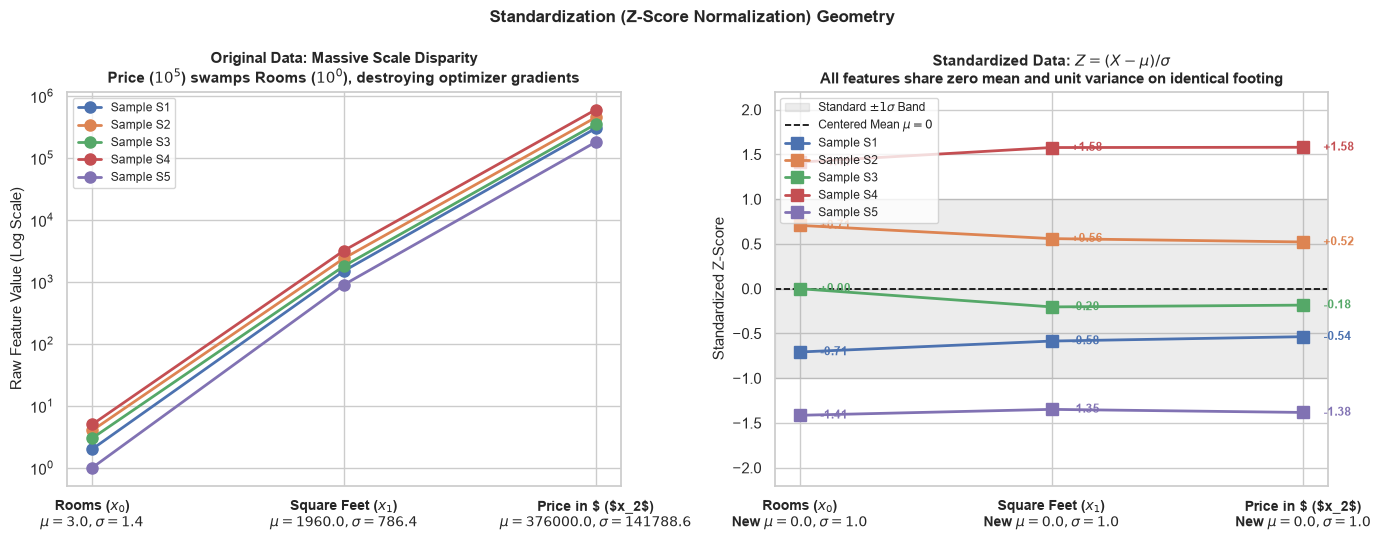

In [8]:
sns.set_theme(style="whitegrid")
palette = sns.color_palette("deep")

# 1. Dataset setup
X = np.array([
    [2.0, 1500.0, 300000.0],
    [4.0, 2400.0, 450000.0],
    [3.0, 1800.0, 350000.0],
    [5.0, 3200.0, 600000.0],
    [1.0,  900.0, 180000.0]
])

# Fixed: Use TeX notation $x_0$, $x_1$, $x_2$ instead of Unicode subscripts
feature_names = [r"Rooms ($x_0$)", r"Square Feet ($x_1$)", r"Price in $ ($x_2$)"]
samples = [f"S{i+1}" for i in range(X.shape[0])]

# Manual standardization
mu = np.mean(X, axis=0)
sigma = np.std(X, axis=0, ddof=0)
epsilon = 1e-5
Z = (X - mu) / (sigma + epsilon)

# 2. Plot setup
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x_coords = np.arange(len(feature_names))
colors = [palette[0], palette[1], palette[2], palette[3], palette[4]]

# -------------------------------------------------------------
# Panel 1: Original Features
# -------------------------------------------------------------
for i in range(X.shape[0]):
    axes[0].plot(
        x_coords, X[i, :], 
        marker='o', markersize=8, linewidth=2, 
        color=colors[i], label=f"Sample {samples[i]}"
    )

axes[0].set_yscale("log")
axes[0].set_xticks(x_coords)
axes[0].set_xticklabels(
    [f"{name}\n" + rf"$\mu={mu[j]:.1f}, \sigma={sigma[j]:.1f}$" for j, name in enumerate(feature_names)],
    fontsize=10, weight="bold"
)
axes[0].set_ylabel("Raw Feature Value (Log Scale)", fontsize=11)
axes[0].set_title(
    "Original Data: Massive Scale Disparity\n"
    r"Price ($10^5$) swamps Rooms ($10^0$), destroying optimizer gradients",
    fontsize=11, weight="bold"
)
axes[0].legend(loc="upper left", frameon=True, fontsize=8.5)

# -------------------------------------------------------------
# Panel 2: Standardized Features (Z-Scores)
# -------------------------------------------------------------
axes[1].axhspan(-1.0, 1.0, color="gray", alpha=0.15, label=r"Standard $\pm 1\sigma$ Band")
axes[1].axhline(0.0, color="black", linestyle="--", linewidth=1.2, label=r"Centered Mean $\mu = 0$")

for i in range(Z.shape[0]):
    axes[1].plot(
        x_coords, Z[i, :], 
        marker='s', markersize=8, linewidth=2, 
        color=colors[i], label=f"Sample {samples[i]}"
    )

# Annotate sample z-scores
for j in range(3):
    for i in range(X.shape[0]):
        val = Z[i, j]
        axes[1].text(
            j + 0.08, val, f"{val:+.2f}",
            fontsize=8.5, weight="bold", color=colors[i], va="center"
        )

axes[1].set_xticks(x_coords)
axes[1].set_xticklabels(
    [f"{name}\n" + r"New $\mu=0.0, \sigma=1.0$" for name in feature_names],
    fontsize=10, weight="bold"
)
axes[1].set_ylim(-2.2, 2.2)
axes[1].set_ylabel("Standardized Z-Score", fontsize=11)
axes[1].set_title(
    r"Standardized Data: $Z = (X - \mu) / \sigma$" + "\n"
    "All features share zero mean and unit variance on identical footing",
    fontsize=11, weight="bold"
)
axes[1].legend(loc="upper left", frameon=True, fontsize=8.5)

fig.suptitle(
    "Standardization (Z-Score Normalization) Geometry",
    fontsize=12, weight="bold"
)

plt.tight_layout()
plt.show()

### Concept 3: Covariance Scaling and Whitening (PCA & ZCA Whitening)

#### What is Data Whitening?

In Concept 2, you learned **Z-Score Standardization**: it centers each feature to mean $0$ and scales each feature to variance $1$.

However, Z-Score standardization operates on each feature column in isolation. If two features are strongly correlated (e.g., height and weight, or adjacent image pixels), they still share redundant information. The covariance matrix still contains large off-diagonal values, resulting in an elongated, tilted distribution cloud.

**Whitening (Sphering) takes standardization to its ultimate conclusion:**

> *"Transform the data so that it has zero mean, each feature has a variance of exactly $1.0$, and **every single feature is completely uncorrelated with every other feature**."*

After whitening:

1. The new covariance matrix becomes the exact **Identity Matrix** ($\Sigma_{\text{white}} = I$).
2. The data cloud transforms into a perfectly round, spherical ball centered at the origin (like white noise, where every frequency or dimension is uncorrelated and equal in energy).

There are two primary methods:

* **PCA Whitening:** Rotates data into its principal component axes (de-correlates), then scales by the singular values/eigenvalues. The resulting axes are aligned with principal components.
* **ZCA Whitening (Zero-phase Component Analysis):** Applies PCA whitening, then **rotates the data right back** to the original coordinate orientation. The result is uncorrelated and spherical, but remains as visually and spatially close to the original input variables as possible.

#### The Formulas

Given a zero-centered data matrix $X$ of shape $(N \times D)$ with covariance matrix $\Sigma$:

**1. Eigen-decomposition of the Covariance Matrix:**


$$\Sigma = V \Lambda V^\top$$

* $V$: Matrix of eigenvectors (columns are principal axes).
* $\Lambda$ (*Lambda*): Diagonal matrix of eigenvalues ($\lambda_1, \lambda_2, \dots, \lambda_D$) representing the variance along each principal axis.

**2. PCA Whitening:**
Rotate onto the eigenvectors $V$, then scale by $\frac{1}{\sqrt{\lambda_i}}$:

$$X_{\text{PCA\_white}} = X V \Lambda^{-\frac{1}{2}}$$

where $\Lambda^{-\frac{1}{2}} = \text{diag}\left(\frac{1}{\sqrt{\lambda_1 + \epsilon}}, \dots, \frac{1}{\sqrt{\lambda_D + \epsilon}}\right)$.

**3. ZCA Whitening:**
Rotate the PCA-whitened data back using $V$:

$$X_{\text{ZCA\_white}} = X_{\text{PCA\_white}} V^\top = X V \Lambda^{-\frac{1}{2}} V^\top$$

#### How to read it out loud:

> *"PCA whitened data equals centered data X multiplied by eigenvector matrix V times the diagonal matrix Lambda to the power of negative one half. ZCA whitened data rotates PCA whitened data back by multiplying with V transposed."*

#### Breakdown of every piece:

* **$X$**: Centered data matrix $(N \times D)$.
* **$V$**: Orthogonal rotation matrix from eigen-decomposition (Notebook 1, Concept 7).
* **$\Lambda^{-\frac{1}{2}}$**: Diagonal scaling matrix. Dividing by $\sqrt{\lambda_i}$ normalizes the variance along principal axis $i$ to exactly $1.0$.
* **$\epsilon$** (*epsilon*, e.g., $10^{-5}$): Whitening regularization constant to prevent division by zero or exploding noise along near-zero variance axes.
* **Covariance check:** Both transformations guarantee that $\text{Cov}(X_{\text{white}}) = I$.

#### Why AI Cares:

* **Image Preprocessing in Classical Vision & Self-Supervised Learning:** Raw natural images have extreme pixel-to-pixel correlation (adjacent pixels almost always share similar color values). ZCA whitening strips out redundant spatial correlation so convolutional filters focus on high-frequency edges and textures rather than illumination.
* **Contrastive Representation Learning & Denoising:** Whitening layers prevent representation collapse in self-supervised feature embeddings by enforcing identity covariance across the embedding dimensions.
* **Eliminating Multi-collinearity:** Linear and logistic models suffer from numerical instability when features correlate heavily; whitening completely removes multi-collinearity.

#### NumPy Implementation

In [9]:
# 1. Generate synthetic 2D data with high correlation
np.random.seed(42)
N = 300
# True covariance with strong cross-feature correlation
true_cov = np.array([
    [4.0, 3.2],
    [3.2, 3.0]
])
raw_data = np.random.multivariate_normal(mean=[10.0, 20.0], cov=true_cov, size=N)

# Step 1: Zero-center the data
X_centered = raw_data - np.mean(raw_data, axis=0)

# Step 2: Compute sample covariance matrix
Sigma = (X_centered.T @ X_centered) / (N - 1)

# Step 3: Eigen-decomposition of the covariance matrix
# eigenvalues (w), eigenvectors (V)
eigenvalues, V = np.linalg.eigh(Sigma)

# Step 4: Construct the inverse square root diagonal scaling matrix
# Adding a small epsilon for numerical stability
epsilon = 1e-5
scale_diag = 1.0 / np.sqrt(eigenvalues + epsilon)
Lambda_inv_sqrt = np.diag(scale_diag)

# ==========================================
# Method A: PCA Whitening
# Formula: X_centered @ V @ Lambda^(-1/2)
# ==========================================
X_pca_white = X_centered @ V @ Lambda_inv_sqrt

# ==========================================
# Method B: ZCA Whitening
# Formula: X_pca_white @ V.T
# ==========================================
X_zca_white = X_pca_white @ V.T

# ==========================================
# Verification: Covariance Matrices after Whitening
# Both should be the 2x2 Identity Matrix: [[1, 0], [0, 1]]
# ==========================================
cov_original = np.cov(raw_data, rowvar=False)
cov_pca_white = np.cov(X_pca_white, rowvar=False)
cov_zca_white = np.cov(X_zca_white, rowvar=False)

print("Original Covariance Matrix (Strong off-diagonal correlation):\n", np.round(cov_original, 3))
print("\nPCA Whitened Covariance Matrix (Should be Identity I):\n", np.round(cov_pca_white, 4))
print("\nZCA Whitened Covariance Matrix (Should be Identity I):\n", np.round(cov_zca_white, 4))
print("\nIs PCA whitening covariance close to Identity?", np.allclose(cov_pca_white, np.eye(2), atol=1e-3))
print("Is ZCA whitening covariance close to Identity?", np.allclose(cov_zca_white, np.eye(2), atol=1e-3))

Original Covariance Matrix (Strong off-diagonal correlation):
 [[3.85  3.069]
 [3.069 2.856]]

PCA Whitened Covariance Matrix (Should be Identity I):
 [[1. 0.]
 [0. 1.]]

ZCA Whitened Covariance Matrix (Should be Identity I):
 [[1. 0.]
 [0. 1.]]

Is PCA whitening covariance close to Identity? True
Is ZCA whitening covariance close to Identity? True


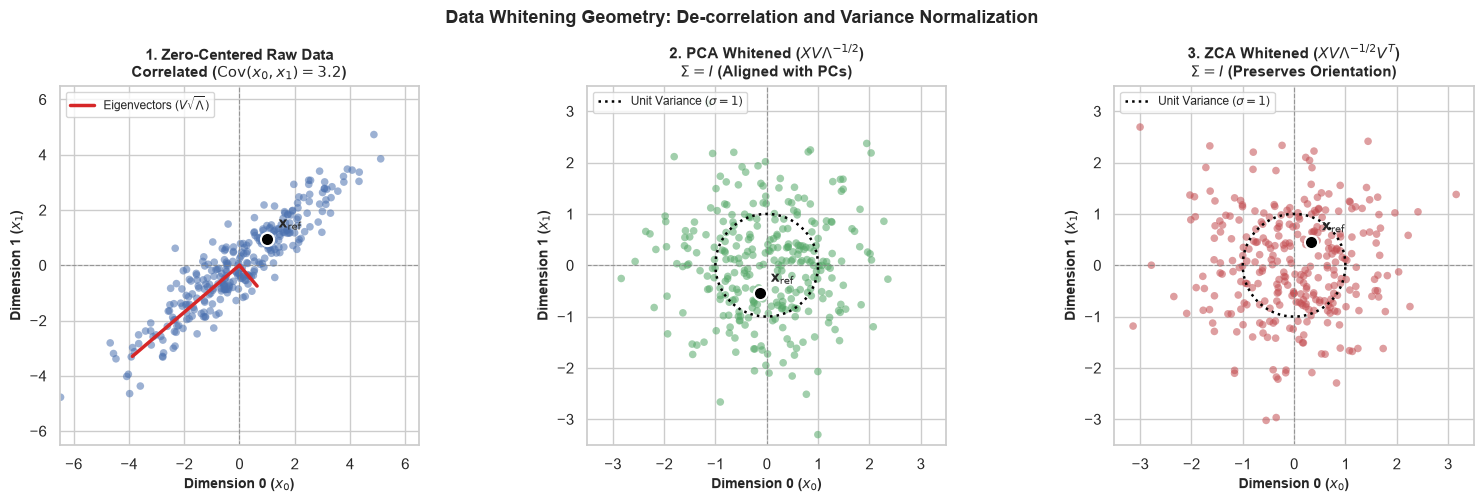

In [11]:
sns.set_theme(style="whitegrid")
palette = sns.color_palette("deep")

# 1. Dataset Generation
np.random.seed(42)
N = 300
true_cov = np.array([
    [4.0, 3.2],
    [3.2, 3.0]
])
raw_data = np.random.multivariate_normal(mean=[10.0, 20.0], cov=true_cov, size=N)

# Step 1: Centering
X_centered = raw_data - np.mean(raw_data, axis=0)

# Step 2: Covariance & Eigendecomposition
Sigma = (X_centered.T @ X_centered) / (N - 1)
eigenvalues, V = np.linalg.eigh(Sigma)

# Step 3: Whitening transforms
epsilon = 1e-5
Lambda_inv_sqrt = np.diag(1.0 / np.sqrt(eigenvalues + epsilon))

# Method A: PCA Whitening
X_pca_white = X_centered @ V @ Lambda_inv_sqrt

# Method B: ZCA Whitening
X_zca_white = X_pca_white @ V.T

# Sample tracking point (to show how whitening rotates individual vectors)
idx_track = 12

# 2. Plotting: 3-panel comparative layout (using raw strings and standard mathtext)
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=False)

datasets = [
    (X_centered, "1. Zero-Centered Raw Data", palette[0], r"Correlated ($\mathrm{Cov}(x_0, x_1) = 3.2$)"),
    (X_pca_white, r"2. PCA Whitened ($X V \Lambda^{-1/2}$)", palette[2], r"$\Sigma = I$ (Aligned with PCs)"),
    (X_zca_white, r"3. ZCA Whitened ($X V \Lambda^{-1/2} V^T$)", palette[3], r"$\Sigma = I$ (Preserves Orientation)")
]

# Unit circle coordinates for visual covariance reference
theta = np.linspace(0, 2 * np.pi, 200)
unit_circle_x = np.cos(theta)
unit_circle_y = np.sin(theta)

for ax, (data_matrix, title, col, cov_label) in zip(axes, datasets):
    # Scatter plot of samples
    ax.scatter(data_matrix[:, 0], data_matrix[:, 1], color=col, alpha=0.55, s=30, edgecolors="none")
    
    # Highlight a tracked point across all 3 spaces
    pt = data_matrix[idx_track]
    ax.scatter([pt[0]], [pt[1]], color="black", s=90, zorder=6, edgecolors="white", linewidth=1.5)
    ax.annotate(
        r"$\mathbf{x}_{\mathrm{ref}}$",
        (pt[0], pt[1]),
        textcoords="offset points", xytext=(8, 8),
        fontsize=10, weight="bold"
    )

    # Reference crosshairs at origin
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)

    # Plot unit variance boundary circle for whitened plots
    if "Whitened" in title:
        ax.plot(unit_circle_x, unit_circle_y, color="black", linestyle=":", linewidth=1.8, label=r"Unit Variance ($\sigma=1$)")
        ax.set_xlim(-3.5, 3.5)
        ax.set_ylim(-3.5, 3.5)
        ax.set_aspect("equal")
        ax.legend(loc="upper left", frameon=True, fontsize=8.5)
    else:
        # Draw eigenvector directions on the raw centered data
        for i in range(2):
            v_dir = V[:, i] * np.sqrt(eigenvalues[i]) * 2.0
            ax.plot([0, v_dir[0]], [0, v_dir[1]], color="#d62728", linewidth=2.5,
                    label=r"Eigenvectors ($V\sqrt{\Lambda}$)" if i == 0 else None)
        ax.set_xlim(-6.5, 6.5)
        ax.set_ylim(-6.5, 6.5)
        ax.set_aspect("equal")
        ax.legend(loc="upper left", frameon=True, fontsize=8.5)

    ax.set_xlabel(r"Dimension 0 ($x_0$)", fontsize=10, weight="bold")
    ax.set_ylabel(r"Dimension 1 ($x_1$)", fontsize=10, weight="bold")
    ax.set_title(f"{title}\n{cov_label}", fontsize=11, weight="bold")

fig.suptitle("Data Whitening Geometry: De-correlation and Variance Normalization", fontsize=13, weight="bold")

plt.tight_layout()
plt.show()

### Concept 4: Kernel Gram Matrices (Non-Linear Similarity)

#### What is a Kernel Gram Matrix?

In Concept 1 of Linear Algebra, you computed the **Dot Product** between two vectors to measure their alignment. In a dataset of $N$ points, if you calculate the dot product between every possible pair of samples, you get an $(N \times N)$ table of similarities called a **Gram Matrix**.

However, simple dot products can only measure **linear** similarity. If your data lives on a circle, a spiral, or complex concentric manifolds, linear comparisons fail to capture the true geometric structure.

**The Kernel Trick solves this without blowing up memory:**

> *"Map low-dimensional points into a higher (or infinite) dimensional space where non-linear patterns become linearly separable, and compute similarities directly using a kernel function $k(\mathbf{x}_i, \mathbf{x}_j)$ without ever explicitly computing the huge feature coordinates."*

The resulting $(N \times N)$ table of kernel evaluations across the entire dataset is the **Kernel Gram Matrix** ($K$).

Common kernels include:

1. **Linear Kernel:** Standard dot product ($K_{i,j} = \mathbf{x}_i \cdot \mathbf{x}_j$).
2. **Polynomial Kernel:** Captures feature interactions up to degree $d$ ($K_{i,j} = (\mathbf{x}_i \cdot \mathbf{x}_j + c)^d$).
3. **Radial Basis Function (RBF / Gaussian Kernel):** Measures similarity using Euclidean distance passed through a bell curve. If two points are identical, similarity is $1.0$; as they move apart, similarity drops smoothly toward $0.0$.

#### The Formulas

For a dataset of $N$ samples $\{\mathbf{x}_1, \mathbf{x}_2, \dots, \mathbf{x}_N\}$:

**1. The Gram Matrix Definition:**


$$K \in \mathbb{R}^{N \times N}, \quad K_{i,j} = k(\mathbf{x}_i, \mathbf{x}_j)$$

**2. Radial Basis Function (RBF / Gaussian) Kernel:**


$$k(\mathbf{x}_i, \mathbf{x}_j) = \exp\left( -\gamma \Vert{}\mathbf{x}_i - \mathbf{x}_j\Vert{}_2^2 \right) = \exp\left( -\frac{\Vert{}\mathbf{x}_i - \mathbf{x}_j\Vert{}_2^2}{2\sigma^2} \right)$$

**3. Vectorized Gram Matrix Construction:**
For the entire dataset matrix $X$ of shape $(N \times D)$, the squared Euclidean distance between all pairs can be expanded algebraically:


$$\Vert{}\mathbf{x}_i - \mathbf{x}_j\Vert{}^2 = \Vert{}\mathbf{x}_i\Vert{}^2 + \Vert{}\mathbf{x}_j\Vert{}^2 - 2(\mathbf{x}_i \cdot \mathbf{x}_j)$$

$$D^2 = \text{diag}(X X^\top)\mathbf{1}^\top + \mathbf{1}\text{diag}(X X^\top)^\top - 2(X X^\top)$$

$$K = \exp\left(-\gamma D^2\right)$$

#### How to read it out loud:

> *"The entry K sub i j of the Gram matrix equals the kernel evaluation between sample x_i and sample x_j. For the RBF kernel, it equals e raised to the power of negative gamma times the squared Euclidean distance between x_i and x_j."*

#### Breakdown of every piece:

* **$K$**: The $(N \times N)$ symmetric Gram matrix. Entry $(i, j)$ is the similarity between sample $i$ and sample $j$.
* **$\Vert{}\mathbf{x}_i - \mathbf{x}_j\Vert{}_2^2$**: The squared Euclidean distance between sample $i$ and sample $j$.
* **$\gamma$** (*gamma*, $\gamma = \frac{1}{2\sigma^2}$): The bandwidth parameter. A large $\gamma$ makes the bell curve narrow (only extremely close neighbors get high similarity); a small $\gamma$ makes similarity fall off slowly.
* **Positive Semi-Definite Property:** By Mercer's Theorem, any valid kernel produces a symmetric matrix with all eigenvalues $\ge 0$, guaranteeing convex optimization.
* **Diagonal Entries ($K_{i,i}$):** The similarity of each point with itself, which for RBF kernels is always $\exp(0) = 1.0$.

#### Why AI Cares:

* **Support Vector Machines (Kernel SVM) & Kernel Ridge Regression:** Enables linear algorithms to construct complex, highly non-linear decision boundaries.
* **Gaussian Processes (GPs):** The Gram matrix serves as the covariance matrix over function values, enabling Bayesian uncertainty estimation in hyperparameter tuning (Bayesian Optimization).
* **Transformer Attention Connection:** Self-Attention computes $S = \text{Softmax}\left(\frac{Q K^\top}{\sqrt{d_k}}\right)$. The unnormalized attention scores $A = Q K^\top$ are structurally a Gram matrix comparing query tokens against key tokens.

#### NumPy Implementation

In [12]:

# 1. Create a tiny dataset: 4 samples, 2 features each
# Points arranged along a 2D line
X = np.array([
    [1.0, 1.0],  # Sample 0
    [1.5, 1.2],  # Sample 1 (Close to sample 0)
    [5.0, 5.0],  # Sample 2 (Far away)
    [5.2, 4.8]   # Sample 3 (Close to sample 2)
])

N = X.shape[0]

# ==========================================
# Method A: Step-by-Step Pairwise Computation
# ==========================================
gamma = 0.5

K_manual = np.zeros((N, N))
for i in range(N):
    for j in range(N):
        # Squared Euclidean distance: sum((x_i - x_j)^2)
        dist_sq = np.sum((X[i] - X[j]) ** 2)
        # RBF Kernel evaluation: exp(-gamma * dist_sq)
        K_manual[i, j] = np.exp(-gamma * dist_sq)

# ==========================================
# Method B: Fully Vectorized NumPy Matrix Formulation
# Using the identity: ||x_i - x_j||^2 = ||x_i||^2 + ||x_j||^2 - 2*(x_i · x_j)
# ==========================================
# 1. Compute dot products between all pairs: X @ X.T (shape: N x N)
dot_matrix = X @ X.T

# 2. Extract squared norms of each row (shape: N x 1)
sq_norms = np.diag(dot_matrix).reshape(-1, 1)

# 3. Broadcast to compute all pairwise squared distances simultaneously
dist_matrix_sq = sq_norms + sq_norms.T - 2.0 * dot_matrix

# 4. Apply element-wise exponential
K_vectorized = np.exp(-gamma * dist_matrix_sq)

# ==========================================
# Inspect Properties of the Gram Matrix
# ==========================================
eigenvalues = np.linalg.eigvalsh(K_vectorized)

print(f"Data Matrix X (Shape: {X.shape}):\n{X}\n")
print(f"Pairwise Squared Distances:\n{np.round(dist_matrix_sq, 3)}\n")
print(f"RBF Kernel Gram Matrix K (gamma = {gamma}):\n{np.round(K_vectorized, 4)}\n")

print(f"Diagonal Entries (Self-similarity): {np.diag(K_vectorized)}")
print(f"Is Gram Matrix Symmetric?          : {np.allclose(K_vectorized, K_vectorized.T)}")
print(f"Eigenvalues (Positive Semi-Definite): {np.round(eigenvalues, 4)}")
print(f"Manual vs Vectorized implementation match: {np.allclose(K_manual, K_vectorized)}")


Data Matrix X (Shape: (4, 2)):
[[1.  1. ]
 [1.5 1.2]
 [5.  5. ]
 [5.2 4.8]]

Pairwise Squared Distances:
[[ 0.    0.29 32.   32.08]
 [ 0.29  0.   26.69 26.65]
 [32.   26.69  0.    0.08]
 [32.08 26.65  0.08  0.  ]]

RBF Kernel Gram Matrix K (gamma = 0.5):
[[1.     0.865  0.     0.    ]
 [0.865  1.     0.     0.    ]
 [0.     0.     1.     0.9608]
 [0.     0.     0.9608 1.    ]]

Diagonal Entries (Self-similarity): [1. 1. 1. 1.]
Is Gram Matrix Symmetric?          : True
Eigenvalues (Positive Semi-Definite): [0.0392 0.135  1.865  1.9608]
Manual vs Vectorized implementation match: True


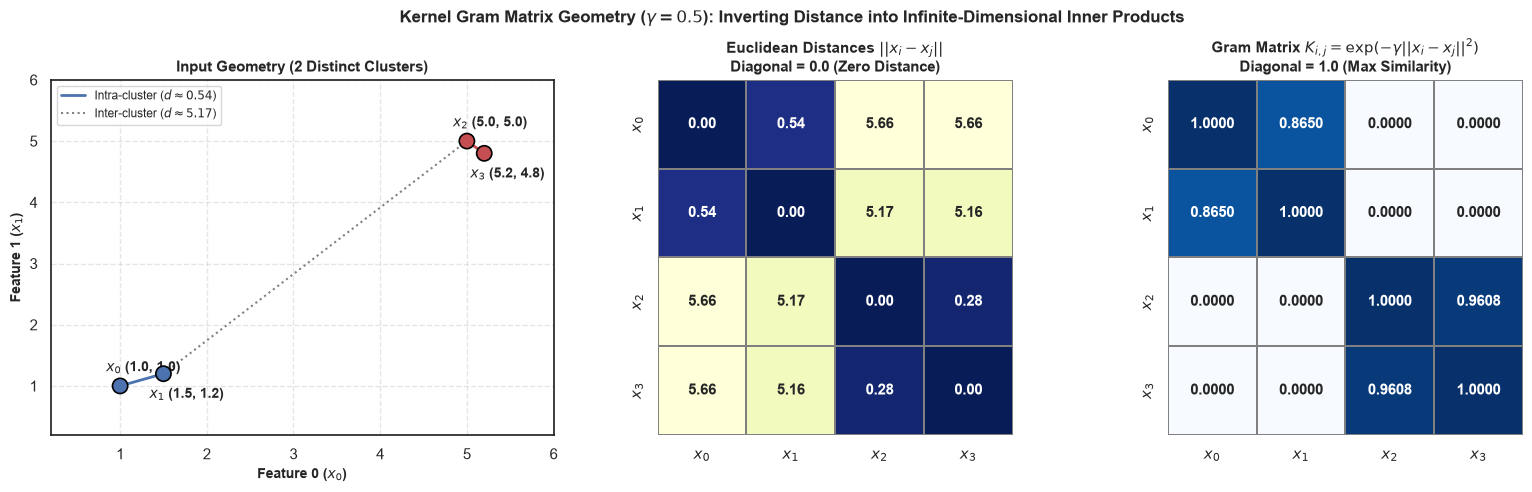

In [13]:
sns.set_theme(style="white")
palette = sns.color_palette("deep")

# 1. Dataset setup
X = np.array([
    [1.0, 1.0],  # Sample 0 (Cluster 1)
    [1.5, 1.2],  # Sample 1 (Cluster 1)
    [5.0, 5.0],  # Sample 2 (Cluster 2)
    [5.2, 4.8]   # Sample 3 (Cluster 2)
])
sample_labels = [r"$x_0$", r"$x_1$", r"$x_2$", r"$x_3$"]
N = X.shape[0]
gamma = 0.5

# Vectorized pairwise squared distance matrix
dot_matrix = X @ X.T
sq_norms = np.diag(dot_matrix).reshape(-1, 1)
dist_matrix_sq = sq_norms + sq_norms.T - 2.0 * dot_matrix
dist_matrix = np.sqrt(np.maximum(dist_matrix_sq, 0.0))

# RBF Kernel Gram Matrix
K = np.exp(-gamma * dist_matrix_sq)

# 2. Plotting: 3-panel layout
fig, axes = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={'width_ratios': [1.1, 1, 1]})

# -------------------------------------------------------------
# Panel 1: Original 2D Data Space (Geometry & Clustering)
# -------------------------------------------------------------
cluster_colors = [palette[0], palette[0], palette[3], palette[3]]
axes[0].grid(True, linestyle="--", alpha=0.5)

# Scatter points
axes[0].scatter(X[:, 0], X[:, 1], color=cluster_colors, s=120, edgecolors="black", linewidth=1.2, zorder=5)

# Draw intra-cluster and inter-cluster connecting lines
axes[0].plot([X[0, 0], X[1, 0]], [X[0, 1], X[1, 1]], color=palette[0], linestyle="-", linewidth=2.0,
             label=r"Intra-cluster ($d \approx 0.54$)")
axes[0].plot([X[2, 0], X[3, 0]], [X[2, 1], X[3, 1]], color=palette[3], linestyle="-", linewidth=2.0)
axes[0].plot([X[1, 0], X[2, 0]], [X[1, 1], X[2, 1]], color="gray", linestyle=":", linewidth=1.5,
             label=r"Inter-cluster ($d \approx 5.17$)")

# Annotate points
for idx, (x_val, y_val) in enumerate(X):
    offset_y = 10 if idx in [0, 2] else -18
    axes[0].annotate(
        f"{sample_labels[idx]} ({x_val:.1f}, {y_val:.1f})",
        (x_val, y_val),
        textcoords="offset points", xytext=(-10, offset_y),
        fontsize=10, weight="bold"
    )

axes[0].set_xlim(0.2, 6.0)
axes[0].set_ylim(0.2, 6.0)
axes[0].set_xlabel(r"Feature 0 ($x_0$)", fontsize=10, weight="bold")
axes[0].set_ylabel(r"Feature 1 ($x_1$)", fontsize=10, weight="bold")
axes[0].set_title("Input Geometry (2 Distinct Clusters)", fontsize=11, weight="bold")
axes[0].legend(loc="upper left", frameon=True, fontsize=8.5)

# -------------------------------------------------------------
# Panel 2: Pairwise Euclidean Distance Matrix
# -------------------------------------------------------------
sns.heatmap(
    dist_matrix,
    annot=True, fmt=".2f", cmap="YlGnBu_r", cbar=False,
    xticklabels=sample_labels, yticklabels=sample_labels,
    linewidths=1.2, linecolor="gray", square=True, ax=axes[1],
    annot_kws={"size": 11, "weight": "bold"}
)
axes[1].set_title(r"Euclidean Distances $||x_i - x_j||$" + "\n" + r"Diagonal = 0.0 (Zero Distance)", fontsize=11, weight="bold")

# -------------------------------------------------------------
# Panel 3: RBF Kernel Gram Matrix K (Similarity)
# -------------------------------------------------------------
sns.heatmap(
    K,
    annot=True, fmt=".4f", cmap="Blues", cbar=False,
    xticklabels=sample_labels, yticklabels=sample_labels,
    linewidths=1.2, linecolor="gray", square=True, ax=axes[2],
    annot_kws={"size": 10.5, "weight": "bold"}
)
axes[2].set_title(r"Gram Matrix $K_{i,j} = \exp(-\gamma ||x_i - x_j||^2)$" + f"\n" + r"Diagonal = 1.0 (Max Similarity)", fontsize=11, weight="bold")

fig.suptitle(r"Kernel Gram Matrix Geometry ($\gamma = 0.5$): Inverting Distance into Infinite-Dimensional Inner Products",
             fontsize=12, weight="bold")

plt.tight_layout()
plt.show()